In [1]:
# STEP 1: INSPECT GLOBAL ELECTRONICS RETAILERS DATA


from pathlib import Path
import duckdb
import pandas as pd

# Locate the Global Electronics Retailers folder
data_folder = (
    Path.home()
    / "Desktop"
    / "supply-chain-portfolio"
    / "kaggle-raw-data"
    / "global-electronics-retailers"
)

# Identify all six CSV files
csv_files = [
    "Sales.csv",
    "Products.csv",
    "Customers.csv",
    "Stores.csv",
    "Exchange_Rates.csv",
    "Data_Dictionary.csv"
]

# Connect to DuckDB
db = duckdb.connect()

print("===== RETAIL DATASET INVENTORY =====")

for filename in csv_files:

    file_path = data_folder / filename

    print(f"\nFile: {filename}")
    print("Found:", file_path.is_file())

    if not file_path.is_file():
        continue

    # Report file size
    file_size = file_path.stat().st_size / 1_000_000

    print("Size (MB):", round(file_size, 2))

    # Read just three example records
    sample = db.execute("""
        SELECT *
        FROM read_csv(
            ?,
            all_varchar = true,
            sample_size = 10000
        )
        LIMIT 3
    """, [str(file_path)]).df()

    # Display columns and examples
    print("Columns:", sample.columns.tolist())

    print("Number of columns:", len(sample.columns))

    display(sample)

print("\n===== INITIAL INSPECTION COMPLETE =====")


===== RETAIL DATASET INVENTORY =====

File: Sales.csv
Found: True
Size (MB): 2.8
Columns: ['Order Number', 'Line Item', 'Order Date', 'Delivery Date', 'CustomerKey', 'StoreKey', 'ProductKey', 'Quantity', 'Currency Code']
Number of columns: 9


,Order Number,Line Item,Order Date,Delivery Date,CustomerKey,StoreKey,ProductKey,Quantity,Currency Code
0,366000,1,1/1/2016,NaN,265598,10,1304,1,CAD
1,366001,1,1/1/2016,1/13/2016,1269051,0,1048,2,USD
2,366001,2,1/1/2016,1/13/2016,1269051,0,2007,1,USD



File: Products.csv
Found: True
Size (MB): 0.3
Columns: ['ProductKey', 'Product Name', 'Brand', 'Color', 'Unit Cost USD', 'Unit Price USD', 'SubcategoryKey', 'Subcategory', 'CategoryKey', 'Category']
Number of columns: 10


,ProductKey,Product Name,Brand,Color,Unit Cost USD,Unit Price USD,SubcategoryKey,Subcategory,CategoryKey,Category
0,1,Contoso 512MB MP3 Player E51 Silver,Contoso,Silver,$6.62,$12.99,0101,MP4&MP3,01,Audio
1,2,Contoso 512MB MP3 Player E51 Blue,Contoso,Blue,$6.62,$12.99,0101,MP4&MP3,01,Audio
2,3,Contoso 1G MP3 Player E100 White,Contoso,White,$7.40,$14.52,0101,MP4&MP3,01,Audio



File: Customers.csv
Found: True
Size (MB): 1.43
Columns: ['CustomerKey', 'Gender', 'Name', 'City', 'State Code', 'State', 'Zip Code', 'Country', 'Continent', 'Birthday']
Number of columns: 10


,CustomerKey,Gender,Name,City,State Code,State,Zip Code,Country,Continent,Birthday
0,301,Female,Lilly Harding,WANDEARAH EAST,SA,South Australia,5523,Australia,Australia,7/3/1939
1,325,Female,Madison Hull,MOUNT BUDD,WA,Western Australia,6522,Australia,Australia,9/27/1979
2,554,Female,Claire Ferres,WINJALLOK,VIC,Victoria,3380,Australia,Australia,5/26/1947


... (3 outputs left out)

,Date,Currency,Exchange
0,1/1/2015,USD,1
1,1/1/2015,CAD,1.1583
2,1/1/2015,AUD,1.2214



File: Data_Dictionary.csv
Found: True
Size (MB): 0.0
Columns: ['Table', 'Field', 'Description']
Number of columns: 3


,Table,Field,Description
0,Sales,Order Number,Unique ID for each order
1,Sales,Line Item,Identifies individual products purchased as pa...
2,Sales,Order Date,Date the order was placed



===== INITIAL INSPECTION COMPLETE =====


In [7]:
# STEP 2: VALIDATE RETAIL SQL TABLE RELATIONSHIPS

from pathlib import Path
import pandas as pd
import duckdb

# ------------------------------------------------------------
# PART 1: LOCATE DATASET
# ------------------------------------------------------------

data_folder = (
    Path.home()
    / "Desktop"
    / "supply-chain-portfolio"
    / "kaggle-raw-data"
    / "global-electronics-retailers"
)

assert data_folder.is_dir(), "Retail dataset folder not found"

# Start a fresh DuckDB connection
db = duckdb.connect(database=":memory:")

# Define CSV files
tables = {
    "retail_sales": "Sales.csv",
    "retail_products": "Products.csv",
    "retail_customers": "Customers.csv",
    "retail_stores": "Stores.csv",
    "retail_rates": "Exchange_Rates.csv",
    "retail_dictionary": "Data_Dictionary.csv"
}


# ------------------------------------------------------------
# PART 2: HANDLE CSV CHARACTER ENCODING
# ------------------------------------------------------------

def load_csv_safely(file_path):

    encodings = ["utf-8-sig", "cp1252", "latin-1"]

    for encoding in encodings:

        try:
            dataframe = pd.read_csv(
                file_path,
                encoding=encoding,
                dtype="string",
                keep_default_na=False,
                na_values=[""],
                low_memory=False
            )

            return dataframe, encoding

        except UnicodeDecodeError:
            continue

    raise ValueError(
        f"Unable to decode: {file_path.name}"
    )


# ------------------------------------------------------------
# PART 3: CREATE SQL TABLES
# ------------------------------------------------------------

print("===== CREATING SQL TABLES =====")

for table_name, filename in tables.items():

    file_path = data_folder / filename

    assert file_path.is_file(), f"Missing: {filename}"

    # Load CSV through Pandas
    dataframe, used_encoding = load_csv_safely(
        file_path
    )

    # Register DataFrame with DuckDB
    db.register("staging_dataframe", dataframe)

    # Create DuckDB table
    db.execute(
        f"""
        CREATE OR REPLACE TEMP TABLE {table_name} AS
        SELECT *
        FROM staging_dataframe
        """
    ).fetchall()

    # Unregister staging DataFrame
    db.unregister("staging_dataframe")

    # Fetch ALL results to clear the DuckDB cursor
    row_count = db.execute(
        f"SELECT COUNT(*) FROM {table_name}"
    ).fetchall()[0][0]

    assert row_count == len(dataframe)

    print(f"\nTable: {table_name}")
    print(f"Rows loaded: {row_count:,}")
    print(f"Encoding: {used_encoding}")

print("\n===== ALL SIX TABLES LOADED SUCCESSFULLY =====")


# ------------------------------------------------------------
# PART 4: VALIDATE PRIMARY KEYS
# ------------------------------------------------------------

print("\n===== PRIMARY KEY VALIDATION =====")

dimension_keys = {
    "retail_products": "ProductKey",
    "retail_customers": "CustomerKey",
    "retail_stores": "StoreKey"
}

for table_name, key in dimension_keys.items():

    duplicate_keys = db.execute(
        f"""
        SELECT COUNT(*)
        FROM (
            SELECT "{key}"
            FROM {table_name}
            GROUP BY "{key}"
            HAVING COUNT(*) > 1
        )
        """
    ).fetchall()[0][0]

    missing_keys = db.execute(
        f"""
        SELECT COUNT(*)
        FROM {table_name}
        WHERE "{key}" IS NULL
           OR TRIM("{key}") = ''
        """
    ).fetchall()[0][0]

    print(f"\nTable: {table_name}")
    print(f"Duplicate key groups: {duplicate_keys}")
    print(f"Missing keys: {missing_keys}")


# ------------------------------------------------------------
# PART 5: VALIDATE SQL JOIN RELATIONSHIPS
# ------------------------------------------------------------

join_validation = db.execute("""
    SELECT
        (SELECT COUNT(*) FROM retail_sales)
            AS Original_Sales_Rows,

        COUNT(*) AS Joined_Rows,

        COUNT(*) FILTER (
            WHERE p.ProductKey IS NULL
        ) AS Unmatched_Products,

        COUNT(*) FILTER (
            WHERE c.CustomerKey IS NULL
        ) AS Unmatched_Customers,

        COUNT(*) FILTER (
            WHERE st.StoreKey IS NULL
        ) AS Unmatched_Stores,

        COUNT(*) FILTER (
            WHERE s.StoreKey = '0'
        ) AS StoreKey_Zero_Rows

    FROM retail_sales AS s

    LEFT JOIN retail_products AS p
        ON s.ProductKey = p.ProductKey

    LEFT JOIN retail_customers AS c
        ON s.CustomerKey = c.CustomerKey

    LEFT JOIN retail_stores AS st
        ON s.StoreKey = st.StoreKey

""").df()

print("\n===== SQL JOIN VALIDATION =====")

display(join_validation)


# ------------------------------------------------------------
# PART 6: INSPECT DATA DICTIONARY
# ------------------------------------------------------------

key_definitions = db.execute("""
    SELECT
        "Table",
        "Field",
        "Description"

    FROM retail_dictionary

    WHERE LOWER("Field") LIKE '%key%'
       OR LOWER("Field") LIKE '%currency%'
       OR LOWER("Field") LIKE '%exchange%'

    LIMIT 30
""").df()

print("\n===== DATA DICTIONARY: KEY DEFINITIONS =====")

display(key_definitions)


# ------------------------------------------------------------
# PART 7: VALIDATE CUSTOMER DATA
# ------------------------------------------------------------

print("\n===== CUSTOMER DATA PREVIEW =====")

customer_preview = db.execute("""
    SELECT
        CustomerKey,
        Name,
        City,
        Country

    FROM retail_customers

    LIMIT 10
""").df()

display(customer_preview)


# ------------------------------------------------------------
# PART 8: FINAL COMPLETION CHECK
# ------------------------------------------------------------

print("\n===== STEP 2 COMPLETE =====")
print("All retail SQL tables created.")
print("Primary keys inspected.")
print("SQL relationships evaluated.")
print("Data dictionary reviewed.")
print("Customer records inspected.")


===== CREATING SQL TABLES =====

Table: retail_sales
Rows loaded: 62,884
Encoding: utf-8-sig

Table: retail_products
Rows loaded: 2,517
Encoding: utf-8-sig

Table: retail_customers
Rows loaded: 15,266
Encoding: cp1252

Table: retail_stores
Rows loaded: 67
Encoding: utf-8-sig

Table: retail_rates
Rows loaded: 11,215
Encoding: utf-8-sig

Table: retail_dictionary
Rows loaded: 37
Encoding: utf-8-sig

===== ALL SIX TABLES LOADED SUCCESSFULLY =====

===== PRIMARY KEY VALIDATION =====

Table: retail_products
Duplicate key groups: 0
Missing keys: 0

Table: retail_customers
Duplicate key groups: 0
Missing keys: 0

Table: retail_stores
Duplicate key groups: 0
Missing keys: 0

===== SQL JOIN VALIDATION =====


,Original_Sales_Rows,Joined_Rows,Unmatched_Products,Unmatched_Customers,Unmatched_Stores,StoreKey_Zero_Rows
0,62884,62884,0,0,0,13165



===== DATA DICTIONARY: KEY DEFINITIONS =====


,Table,Field,Description
0,Sales,CustomerKey,Unique key identifying which customer placed t...
1,Sales,StoreKey,Unique key identifying which store processed t...
2,Sales,ProductKey,Unique key identifying which product was purch...
3,Sales,Currency Code,Currency used to process the order
4,Customers,CustomerKey,Primary key to identify customers
5,Products,ProductKey,Primary key to identify products
6,Products,SubcategoryKey,Key to identify product subcategories
7,Products,CategoryKey,Key to identify product categories
8,Stores,StoreKey,Primary key to identify stores
9,Exchange Rates,Currency,Currency code



===== CUSTOMER DATA PREVIEW =====


,CustomerKey,Name,City,Country
0,301,Lilly Harding,WANDEARAH EAST,Australia
1,325,Madison Hull,MOUNT BUDD,Australia
2,554,Claire Ferres,WINJALLOK,Australia
3,786,Jai Poltpalingada,MIDDLE RIVER,Australia
4,1042,Aidan Pankhurst,TAWONGA SOUTH,Australia
5,1086,Hayden Clegg,TEMPLERS,Australia
6,1133,Nicholas Caffyn,JUBILEE POCKET,Australia
7,1256,Lincoln Jenks,KULLOGUM,Australia
8,1314,Isaac Israel,EDITH RIVER,Australia
9,1568,Luke Virtue,KOTTA,Australia



===== STEP 2 COMPLETE =====
All retail SQL tables created.
Primary keys inspected.
SQL relationships evaluated.
Data dictionary reviewed.
Customer records inspected.


In [8]:

# STEP 3: BUILD JOINED RETAIL SALES DATASET


# First investigate StoreKey = 0
print("===== STOREKEY ZERO INVESTIGATION =====")

store_zero = db.execute("""
    SELECT *
    FROM retail_stores
    WHERE StoreKey = '0'
""").df()

display(store_zero)


# ------------------------------------------------------------
# CREATE ENRICHED RETAIL SALES TABLE
# ------------------------------------------------------------

db.execute("""
    CREATE OR REPLACE TEMP TABLE retail_sales_enriched AS

    SELECT
        s."Order Number" AS Order_Number,
        s."Line Item" AS Line_Item,

        TRY_STRPTIME(
            s."Order Date",
            '%m/%d/%Y'
        )::DATE AS Order_Date,

        s.CustomerKey,
        s.ProductKey,
        s.StoreKey,

        TRY_CAST(s.Quantity AS INTEGER) AS Quantity,

        s."Currency Code" AS Currency_Code,

        p."Product Name" AS Product_Name,
        p.Brand,
        p.Category,
        p.Subcategory,

        TRY_CAST(
            REPLACE(
                REPLACE(p."Unit Price USD", '$', ''),
                ',', ''
            ) AS DECIMAL(18,2)
        ) AS Unit_Price_USD,

        c.Country AS Customer_Country,
        c.Continent AS Customer_Continent,

        st.Country AS Store_Country,
        st.State AS Store_State

    FROM retail_sales AS s

    LEFT JOIN retail_products AS p
        ON s.ProductKey = p.ProductKey

    LEFT JOIN retail_customers AS c
        ON s.CustomerKey = c.CustomerKey

    LEFT JOIN retail_stores AS st
        ON s.StoreKey = st.StoreKey

""").fetchall()


# ------------------------------------------------------------
# VALIDATE JOINED DATASET
# ------------------------------------------------------------

validation = db.execute("""
    SELECT
        COUNT(*) AS Total_Rows,

        COUNT(*) FILTER (
            WHERE Order_Date IS NULL
        ) AS Invalid_Order_Dates,

        COUNT(*) FILTER (
            WHERE Quantity IS NULL
               OR Quantity <= 0
        ) AS Invalid_Quantities,

        COUNT(*) FILTER (
            WHERE Unit_Price_USD IS NULL
        ) AS Missing_Prices,

        COUNT(*) FILTER (
            WHERE Product_Name IS NULL
        ) AS Missing_Products

    FROM retail_sales_enriched
""").df()

print("\n===== JOINED DATASET VALIDATION =====")
display(validation)


# ------------------------------------------------------------
# PREVIEW ENRICHED SALES RECORDS
# ------------------------------------------------------------

sales_preview = db.execute("""
    SELECT
        Order_Date,
        Product_Name,
        Brand,
        Category,
        Quantity,
        Unit_Price_USD,
        Customer_Country,
        Store_Country

    FROM retail_sales_enriched

    LIMIT 10
""").df()

print("\n===== ENRICHED SALES PREVIEW =====")
display(sales_preview)


# ------------------------------------------------------------
# CHECK TRANSACTION DATE COVERAGE
# ------------------------------------------------------------

date_summary = db.execute("""
    SELECT
        MIN(Order_Date) AS Earliest_Order,
        MAX(Order_Date) AS Latest_Order,
        COUNT(DISTINCT ProductKey) AS Unique_Products,
        COUNT(DISTINCT CustomerKey) AS Unique_Customers

    FROM retail_sales_enriched
""").df()

print("\n===== RETAIL DATASET COVERAGE =====")
display(date_summary)

print("\n===== STEP 3 COMPLETE =====")


===== STOREKEY ZERO INVESTIGATION =====


,StoreKey,Country,State,Square Meters,Open Date
0,0,Online,Online,None,1/1/2010



===== JOINED DATASET VALIDATION =====


,Total_Rows,Invalid_Order_Dates,Invalid_Quantities,Missing_Prices,Missing_Products
0,62884,0,0,0,0



===== ENRICHED SALES PREVIEW =====


,Order_Date,Product_Name,Brand,Category,Quantity,Unit_Price_USD,Customer_Country,Store_Country
0,2016-01-01,Contoso Lens Adapter M450 White,Contoso,Cameras and camcorders,1,68.00,Canada,Canada
1,2016-01-01,A. Datum SLR Camera X136 Silver,A. Datum,Cameras and camcorders,2,427.00,United States,Online
2,2016-01-01,Fabrikam Microwave 1.5CuFt X1100 Black,Fabrikam,Home Appliances,1,665.94,United States,Online
3,2016-01-01,Contoso SLR Camera M146 Orange,Contoso,Cameras and camcorders,7,322.00,Canada,Online
4,2016-01-01,Adventure Works Laptop8.9 E0890 White,Adventure Works,Computers,1,326.00,Canada,Online
5,2016-01-01,Contoso SLR Camera X143 Silver,Contoso,Cameras and camcorders,4,646.00,Canada,Online
6,2016-01-01,"Adventure Works 52"" LCD HDTV X790W White",Adventure Works,TV and Video,6,1592.20,United Kingdom,United Kingdom
7,2016-01-01,The Phone Company PDA Handheld 3.5 inch M610 B...,The Phone Company,Cell phones,2,255.00,United Kingdom,United Kingdom
8,2016-01-01,Adventure Works Desktop PC3.0 MS300 Silver,Adventure Works,Computers,4,469.00,Netherlands,Netherlands
9,2016-01-01,Contoso DVD Player M110 Silver,Contoso,"Music, Movies and Audio Books",1,57.99,United States,United States



===== RETAIL DATASET COVERAGE =====


,Earliest_Order,Latest_Order,Unique_Products,Unique_Customers
0,2016-01-01,2021-02-20,2492,11887



===== STEP 3 COMPLETE =====


In [9]:
# STEP 4: ANALYZE PRODUCT AND CATEGORY DEMAND

# ------------------------------------------------------------
# PART 1: ANALYZE DEMAND BY PRODUCT CATEGORY
# ------------------------------------------------------------

category_demand = db.execute("""
    SELECT
        Category,

        SUM(Quantity) AS Units_Sold,

        COUNT(DISTINCT Order_Number) AS Total_Orders,

        COUNT(DISTINCT ProductKey) AS Unique_Products

    FROM retail_sales_enriched

    WHERE Quantity > 0

    GROUP BY Category

    ORDER BY Units_Sold DESC
""").df()

print("===== PRODUCT CATEGORY DEMAND =====")
display(category_demand)


# ------------------------------------------------------------
# PART 2: IDENTIFY TOP 15 PRODUCTS BY UNITS SOLD
# ------------------------------------------------------------

top_products = db.execute("""
    SELECT
        ProductKey,
        Product_Name,
        Brand,
        Category,

        SUM(Quantity) AS Units_Sold,

        COUNT(DISTINCT Order_Number) AS Total_Orders

    FROM retail_sales_enriched

    WHERE Quantity > 0

    GROUP BY
        ProductKey,
        Product_Name,
        Brand,
        Category

    ORDER BY Units_Sold DESC

    LIMIT 15
""").df()

print("\n===== TOP 15 PRODUCTS BY UNITS SOLD =====")
display(top_products)


# ------------------------------------------------------------
# PART 3: VALIDATE TOTAL PRODUCT DEMAND
# ------------------------------------------------------------

total_units = db.execute("""
    SELECT
        COUNT(*) AS Sales_Lines,

        SUM(Quantity) AS Total_Units_Sold,

        COUNT(DISTINCT Order_Number) AS Unique_Orders,

        COUNT(DISTINCT ProductKey) AS Products_Sold

    FROM retail_sales_enriched
""").df()

print("\n===== OVERALL RETAIL DEMAND SUMMARY =====")
display(total_units)

print("\n===== STEP 4 COMPLETE =====")


===== PRODUCT CATEGORY DEMAND =====


,Category,Units_Sold,Total_Orders,Unique_Products
0,Computers,44151.0,10990,606
1,Cell phones,31477.0,8442,285
2,"Music, Movies and Audio Books",28802.0,7784,90
3,Audio,23490.0,6625,115
4,Games and Toys,22591.0,6128,166
5,Home Appliances,18401.0,5195,637
6,Cameras and camcorders,17609.0,4995,372
7,TV and Video,11236.0,3325,221



===== TOP 15 PRODUCTS BY UNITS SOLD =====


,ProductKey,Product_Name,Brand,Category,Units_Sold,Total_Orders
0,444,WWI Desktop PC2.33 X2330 Black,Wide World Importers,Computers,550.0,154
1,458,WWI Desktop PC1.80 E1800 White,Wide World Importers,Computers,538.0,158
2,424,Adventure Works Desktop PC1.60 ED160 Black,Adventure Works,Computers,521.0,154
3,434,Adventure Works Desktop PC2.30 MD230 White,Adventure Works,Computers,521.0,157
4,425,Adventure Works Desktop PC1.80 ED180 Black,Adventure Works,Computers,520.0,146
5,423,Adventure Works Desktop PC2.30 MD230 Black,Adventure Works,Computers,514.0,160
6,446,WWI Desktop PC1.60 E1600 Black,Wide World Importers,Computers,509.0,158
7,440,WWI Desktop PC1.60 E1600 Silver,Wide World Importers,Computers,507.0,154
8,435,Adventure Works Desktop PC1.60 ED160 White,Adventure Works,Computers,505.0,146
9,448,WWI Desktop PC1.80 E1801 Black,Wide World Importers,Computers,505.0,156



===== OVERALL RETAIL DEMAND SUMMARY =====


,Sales_Lines,Total_Units_Sold,Unique_Orders,Products_Sold
0,62884,197757.0,26326,2492



===== STEP 4 COMPLETE =====


In [10]:
# STEP 5: ANALYZE GEOGRAPHIC DEMAND AND SALES CHANNELS

# ------------------------------------------------------------
# PART 1: ANALYZE DEMAND BY CUSTOMER COUNTRY
# ------------------------------------------------------------

country_demand = db.execute("""
    SELECT
        Customer_Country AS Country,

        SUM(Quantity) AS Units_Sold,

        COUNT(DISTINCT Order_Number) AS Total_Orders,

        COUNT(DISTINCT ProductKey) AS Unique_Products,

        ROUND(
            SUM(Quantity) * 100.0 /
            SUM(SUM(Quantity)) OVER (),
            2
        ) AS Share_of_Units_Pct

    FROM retail_sales_enriched

    GROUP BY Customer_Country

    ORDER BY Units_Sold DESC
""").df()

print("===== GEOGRAPHIC DEMAND BY CUSTOMER COUNTRY =====")

display(country_demand)


# ------------------------------------------------------------
# PART 2: ANALYZE ONLINE VS PHYSICAL STORE DEMAND
# ------------------------------------------------------------

channel_demand = db.execute("""
    SELECT

        CASE
            WHEN StoreKey = '0' THEN 'Online'
            ELSE 'Physical Store'
        END AS Sales_Channel,

        COUNT(*) AS Sales_Lines,

        SUM(Quantity) AS Units_Sold,

        COUNT(DISTINCT Order_Number) AS Total_Orders,

        ROUND(
            SUM(Quantity) * 100.0 /
            SUM(SUM(Quantity)) OVER (),
            2
        ) AS Share_of_Units_Pct

    FROM retail_sales_enriched

    GROUP BY Sales_Channel

    ORDER BY Units_Sold DESC
""").df()

print("\n===== ONLINE VS PHYSICAL STORE DEMAND =====")

display(channel_demand)


# ------------------------------------------------------------
# PART 3: ANALYZE SALES CHANNELS BY CUSTOMER COUNTRY
# ------------------------------------------------------------

country_channel = db.execute("""
    SELECT

        Customer_Country AS Country,

        CASE
            WHEN StoreKey = '0' THEN 'Online'
            ELSE 'Physical Store'
        END AS Sales_Channel,

        SUM(Quantity) AS Units_Sold,

        COUNT(DISTINCT Order_Number) AS Total_Orders

    FROM retail_sales_enriched

    GROUP BY
        Customer_Country,
        Sales_Channel

    ORDER BY
        Country,
        Units_Sold DESC
""").df()

print("\n===== COUNTRY AND SALES CHANNEL COMPARISON =====")

display(country_channel)


# ------------------------------------------------------------
# PART 4: VALIDATE GEOGRAPHIC DEMAND TOTALS
# ------------------------------------------------------------

original_units = db.execute("""
    SELECT SUM(Quantity)
    FROM retail_sales_enriched
""").fetchone()[0]

country_units = country_demand["Units_Sold"].sum()

channel_units = channel_demand["Units_Sold"].sum()

print("\n===== GEOGRAPHIC DATA VALIDATION =====")

print("Original units:", original_units)
print("Country total:", country_units)
print("Channel total:", channel_units)

print(
    "Country totals match:",
    original_units == country_units
)

print(
    "Channel totals match:",
    original_units == channel_units
)

print("\n===== STEP 5 COMPLETE =====")


===== GEOGRAPHIC DEMAND BY CUSTOMER COUNTRY =====


,Country,Units_Sold,Total_Orders,Unique_Products,Share_of_Units_Pct
0,United States,106407.0,14221,2437,53.81
1,United Kingdom,25298.0,3421,1969,12.79
2,Germany,18943.0,2440,1791,9.58
3,Canada,16793.0,2281,1739,8.49
4,Australia,9209.0,1182,1315,4.66
5,Italy,8470.0,1101,1275,4.28
6,Netherlands,7252.0,976,1178,3.67
7,France,5385.0,704,982,2.72



===== ONLINE VS PHYSICAL STORE DEMAND =====


,Sales_Channel,Sales_Lines,Units_Sold,Total_Orders,Share_of_Units_Pct
0,Physical Store,49719,156446.0,20746,79.11
1,Online,13165,41311.0,5580,20.89



===== COUNTRY AND SALES CHANNEL COMPARISON =====


,Country,Sales_Channel,Units_Sold,Total_Orders
0,Australia,Physical Store,7085.0,901
1,Australia,Online,2124.0,281
2,Canada,Physical Store,12991.0,1769
3,Canada,Online,3802.0,512
4,France,Physical Store,4332.0,571
5,France,Online,1053.0,133
6,Germany,Physical Store,14880.0,1902
7,Germany,Online,4063.0,538
8,Italy,Physical Store,6986.0,890
9,Italy,Online,1484.0,211



===== GEOGRAPHIC DATA VALIDATION =====
Original units: 197757
Country total: 197757.0
Channel total: 197757.0
Country totals match: True
Channel totals match: True

===== STEP 5 COMPLETE =====


In [11]:
# STEP 6: ANALYZE HISTORICAL RETAIL DEMAND TRENDS


import pandas as pd

# ------------------------------------------------------------
# PART 1: MONTHLY RETAIL DEMAND
# ------------------------------------------------------------

monthly_demand = db.execute("""
    SELECT
        DATE_TRUNC('month', Order_Date)::DATE AS Month,

        EXTRACT(YEAR FROM Order_Date) AS Year,

        EXTRACT(MONTH FROM Order_Date) AS Month_Number,

        SUM(Quantity) AS Units_Sold,

        COUNT(DISTINCT Order_Number) AS Total_Orders,

        COUNT(DISTINCT ProductKey) AS Unique_Products

    FROM retail_sales_enriched

    WHERE Order_Date IS NOT NULL

    GROUP BY
        1, 2, 3

    ORDER BY Month
""").df()

print("===== MONTHLY RETAIL DEMAND =====")

print("Months with recorded sales:", len(monthly_demand))

display(monthly_demand.head(12))

print("\n===== LATEST 12 MONTHS =====")

display(monthly_demand.tail(12))


# ------------------------------------------------------------
# PART 2: YEARLY RETAIL DEMAND
# ------------------------------------------------------------

yearly_demand = db.execute("""
    SELECT
        EXTRACT(YEAR FROM Order_Date) AS Year,

        SUM(Quantity) AS Units_Sold,

        COUNT(DISTINCT Order_Number) AS Total_Orders,

        COUNT(DISTINCT ProductKey) AS Unique_Products,

        COUNT(
            DISTINCT DATE_TRUNC('month', Order_Date)
        ) AS Months_With_Sales,

        MIN(Order_Date) AS First_Order_Date,

        MAX(Order_Date) AS Last_Order_Date

    FROM retail_sales_enriched

    WHERE Order_Date IS NOT NULL

    GROUP BY Year

    ORDER BY Year
""").df()

print("\n===== YEARLY RETAIL DEMAND =====")

display(yearly_demand)


# ------------------------------------------------------------
# PART 3: IDENTIFY HIGHEST-DEMAND MONTHS
# ------------------------------------------------------------

top_months = (
    monthly_demand
    .sort_values("Units_Sold", ascending=False)
    .head(10)
)

print("\n===== TOP 10 MONTHS BY UNIT SALES =====")

display(top_months)


# ------------------------------------------------------------
# PART 4: VALIDATE MONTHLY AGGREGATION
# ------------------------------------------------------------

original_units = db.execute("""
    SELECT SUM(Quantity)
    FROM retail_sales_enriched
""").fetchone()[0]

monthly_total = monthly_demand["Units_Sold"].sum()

yearly_total = yearly_demand["Units_Sold"].sum()

print("\n===== DEMAND DATA VALIDATION =====")

print("Original units:", original_units)
print("Monthly total:", monthly_total)
print("Yearly total:", yearly_total)

print(
    "Monthly totals match:",
    original_units == monthly_total
)

print(
    "Yearly totals match:",
    original_units == yearly_total
)

print("\n===== STEP 6 COMPLETE =====")


===== MONTHLY RETAIL DEMAND =====
Months with recorded sales: 62


,Month,Year,Month_Number,Units_Sold,Total_Orders,Unique_Products
0,2016-01-01,2016,1,2116.0,292,512
1,2016-02-01,2016,2,2676.0,334,610
2,2016-03-01,2016,3,895.0,109,249
3,2016-04-01,2016,4,326.0,41,104
4,2016-05-01,2016,5,1646.0,220,416
5,2016-06-01,2016,6,1864.0,243,458
6,2016-07-01,2016,7,1572.0,201,421
7,2016-08-01,2016,8,1611.0,229,422
8,2016-09-01,2016,9,1885.0,262,483
9,2016-10-01,2016,10,2042.0,258,489



===== LATEST 12 MONTHS =====


,Month,Year,Month_Number,Units_Sold,Total_Orders,Unique_Products
50,2020-03-01,2020,3,2392.0,332,552
51,2020-04-01,2020,4,694.0,80,196
52,2020-05-01,2020,5,3256.0,455,740
53,2020-06-01,2020,6,2738.0,357,608
54,2020-07-01,2020,7,1941.0,253,471
55,2020-08-01,2020,8,1526.0,201,400
56,2020-09-01,2020,9,1328.0,180,352
57,2020-10-01,2020,10,1042.0,159,289
58,2020-11-01,2020,11,1044.0,149,291
59,2020-12-01,2020,12,2411.0,318,547



===== YEARLY RETAIL DEMAND =====


,Year,Units_Sold,Total_Orders,Unique_Products,Months_With_Sales,First_Order_Date,Last_Order_Date
0,2016,21761.0,2865,1932,12,2016-01-01,2016-12-31
1,2017,24798.0,3280,1997,12,2017-01-01,2017-12-31
2,2018,44498.0,5965,2251,12,2018-01-01,2018-12-31
3,2019,68440.0,9083,2288,12,2019-01-01,2019-12-31
4,2020,34463.0,4635,2001,12,2020-01-01,2020-12-31
5,2021,3797.0,498,784,2,2021-01-01,2021-02-20



===== TOP 10 MONTHS BY UNIT SALES =====


,Month,Year,Month_Number,Units_Sold,Total_Orders,Unique_Products
47,2019-12-01,2019,12,9343.0,1250,1311
49,2020-02-01,2020,2,8385.0,1124,1182
35,2018-12-01,2018,12,7837.0,1089,1213
48,2020-01-01,2020,1,7706.0,1027,1154
37,2019-02-01,2019,2,7383.0,967,1130
36,2019-01-01,2019,1,6850.0,892,1122
45,2019-10-01,2019,10,6412.0,842,1076
46,2019-11-01,2019,11,6045.0,801,999
44,2019-09-01,2019,9,6037.0,781,991
40,2019-05-01,2019,5,5966.0,808,1038



===== DEMAND DATA VALIDATION =====
Original units: 197757
Monthly total: 197757.0
Yearly total: 197757.0
Monthly totals match: True
Yearly totals match: True

===== STEP 6 COMPLETE =====


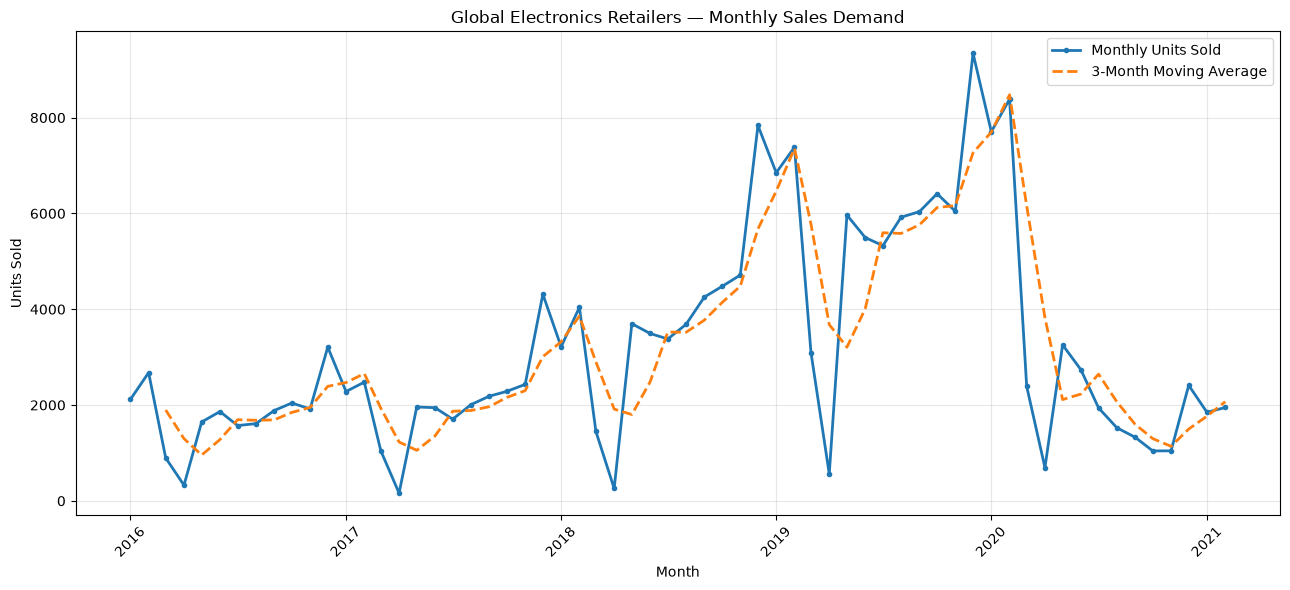

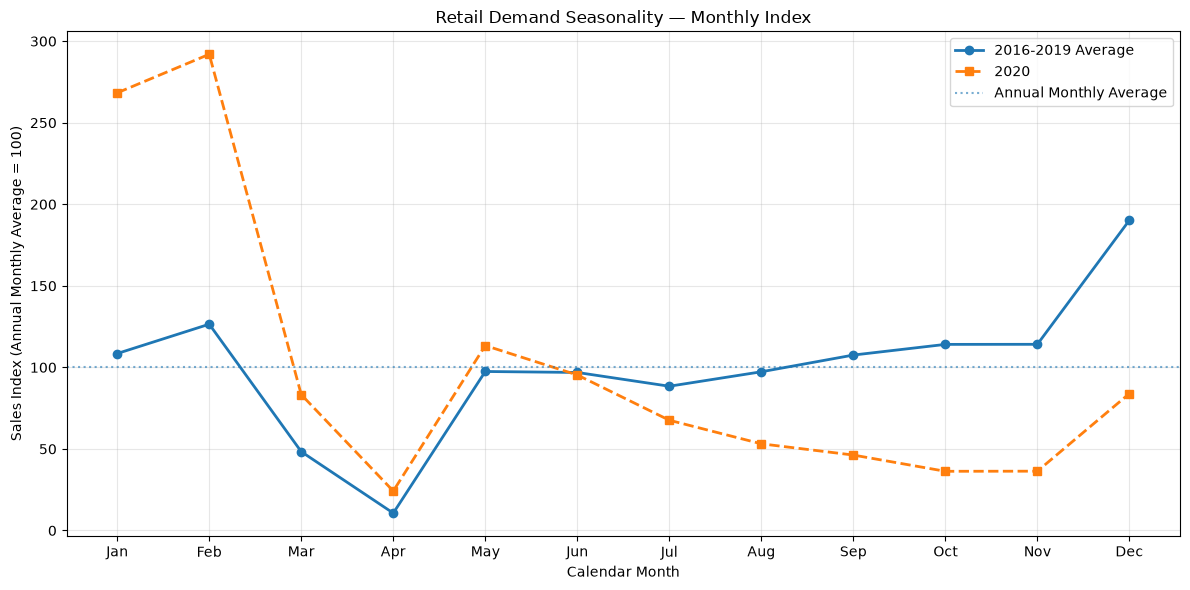

===== HISTORICAL SEASONAL DEMAND INDEX =====


,Month_Number,Seasonal_Index
0,1,108.49
1,2,126.47
2,3,48.32
3,4,10.64
4,5,97.47
5,6,96.88
6,7,88.43
7,8,97.30
8,9,107.55
9,10,114.09



===== HIGHEST MONTHLY DEMAND =====
Month: 2019-12-01 00:00:00
Units sold: 9343.0

===== STEP 7 COMPLETE =====


In [12]:
# STEP 7: VISUALIZE RETAIL DEMAND AND SEASONALITY

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PART 1: PREPARE MONTHLY SALES DATA
# ------------------------------------------------------------

monthly_plot = monthly_demand.copy()

monthly_plot["Month"] = pd.to_datetime(
    monthly_plot["Month"]
)

monthly_plot["Year"] = (
    monthly_plot["Year"].astype(int)
)

monthly_plot = monthly_plot.sort_values("Month")

# ------------------------------------------------------------
# PART 2: VISUALIZE HISTORICAL MONTHLY DEMAND
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

plt.plot(
    monthly_plot["Month"],
    monthly_plot["Units_Sold"],
    marker="o",
    markersize=3,
    linewidth=2,
    label="Monthly Units Sold"
)

# Add a three-month moving average
monthly_plot["Moving_Avg_3M"] = (
    monthly_plot["Units_Sold"]
    .rolling(window=3)
    .mean()
)

plt.plot(
    monthly_plot["Month"],
    monthly_plot["Moving_Avg_3M"],
    linestyle="--",
    linewidth=2,
    label="3-Month Moving Average"
)

plt.title(
    "Global Electronics Retailers — Monthly Sales Demand"
)

plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# PART 3: CREATE SEASONAL DEMAND INDEX
# ------------------------------------------------------------

# Exclude incomplete 2021 data
seasonal_data = monthly_plot[
    monthly_plot["Year"].between(2016, 2020)
].copy()

# Normalize sales relative to each year's monthly average
seasonal_data["Seasonal_Index"] = (
    seasonal_data["Units_Sold"]
    /
    seasonal_data.groupby("Year")["Units_Sold"]
    .transform("mean")
    * 100
)

# Average 2016-2019 monthly seasonal index
historical_seasonality = (
    seasonal_data[
        seasonal_data["Year"].between(2016, 2019)
    ]
    .groupby("Month_Number", as_index=False)
    ["Seasonal_Index"]
    .mean()
)

# Separate 2020 for comparison
seasonality_2020 = seasonal_data[
    seasonal_data["Year"] == 2020
].copy()

# ------------------------------------------------------------
# PART 4: VISUALIZE SEASONAL PATTERNS
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    historical_seasonality["Month_Number"],
    historical_seasonality["Seasonal_Index"],
    marker="o",
    linewidth=2,
    label="2016-2019 Average"
)

plt.plot(
    seasonality_2020["Month_Number"],
    seasonality_2020["Seasonal_Index"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="2020"
)

plt.axhline(
    y=100,
    linestyle=":",
    alpha=0.6,
    label="Annual Monthly Average"
)

plt.title(
    "Retail Demand Seasonality — Monthly Index"
)

plt.xlabel("Calendar Month")
plt.ylabel("Sales Index (Annual Monthly Average = 100)")

plt.xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# PART 5: DISPLAY SEASONALITY TABLE
# ------------------------------------------------------------

print("===== HISTORICAL SEASONAL DEMAND INDEX =====")

display(
    historical_seasonality.round(2)
)

print("\n===== HIGHEST MONTHLY DEMAND =====")

peak_month = monthly_plot.loc[
    monthly_plot["Units_Sold"].idxmax()
]

print("Month:", peak_month["Month"])
print("Units sold:", peak_month["Units_Sold"])

print("\n===== STEP 7 COMPLETE =====")


===== MONTHLY ELECTRONICS CATEGORY DEMAND =====


,Month,Category,Units_Sold,Total_Orders
0,2019-01-01,Audio,864.0,251
1,2019-01-01,Cameras and camcorders,592.0,158
2,2019-01-01,Cell phones,1241.0,321
3,2019-01-01,Computers,1601.0,370
4,2019-02-01,Audio,940.0,258
5,2019-02-01,Cameras and camcorders,628.0,167
6,2019-02-01,Cell phones,1286.0,331
7,2019-02-01,Computers,1811.0,439
8,2019-03-01,Audio,390.0,104
9,2019-03-01,Cameras and camcorders,233.0,78



===== CATEGORY DEMAND COMPARISON =====


Category,Audio,Cameras and camcorders,Cell phones,Computers
Month,,,,
2019-01-01,864.0,592.0,1241.0,1601.0
2019-02-01,940.0,628.0,1286.0,1811.0
2019-03-01,390.0,233.0,450.0,696.0
2019-04-01,46.0,79.0,125.0,141.0
2019-05-01,719.0,562.0,1076.0,1388.0
2019-06-01,613.0,562.0,888.0,1278.0
2019-07-01,689.0,404.0,932.0,1335.0
2019-08-01,733.0,510.0,924.0,1471.0
2019-09-01,672.0,636.0,1022.0,1366.0



===== CATEGORY SEASONAL INDEX =====


Category,Audio,Cameras and camcorders,Cell phones,Computers
Month,,,,
2019-01-01,130.27,114.45,126.98,118.57
2019-02-01,141.73,121.41,131.58,134.12
2019-03-01,58.80,45.05,46.04,51.55
2019-04-01,6.94,15.27,12.79,10.44
2019-05-01,108.41,108.65,110.10,102.80
2019-06-01,92.42,108.65,90.86,94.65
2019-07-01,103.88,78.11,95.36,98.87
2019-08-01,110.52,98.60,94.54,108.94
2019-09-01,101.32,122.96,104.57,101.17


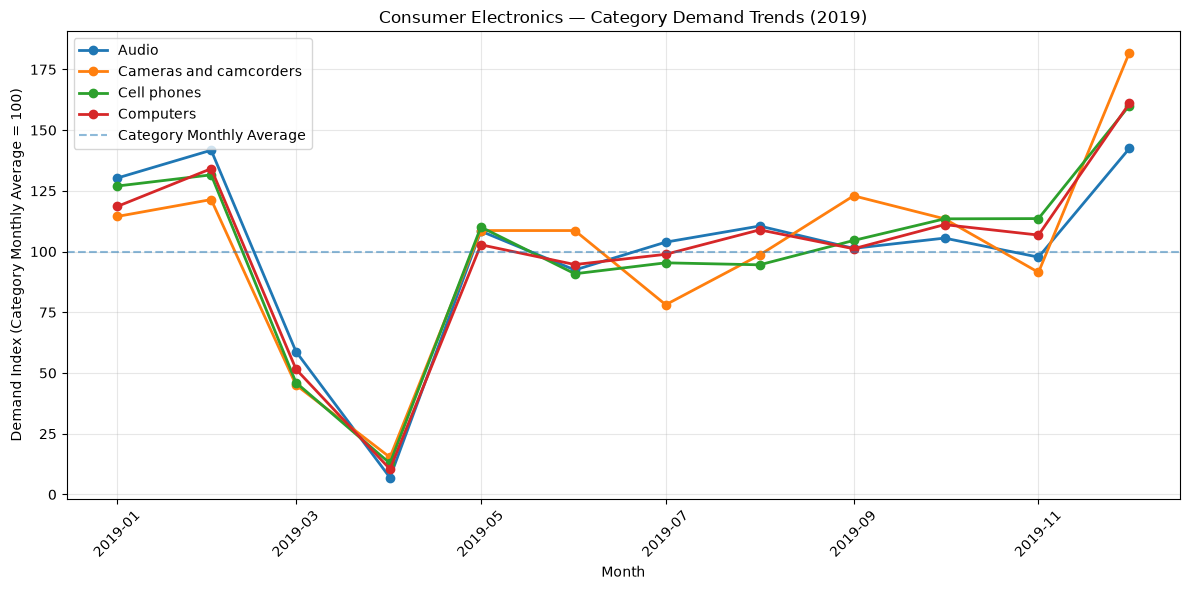


===== MARCH / APRIL / MAY DATA COVERAGE =====


,Year,Month_Number,Days_With_Sales,Total_Orders,Units_Sold
0,2016,3,15,109,895.0
1,2016,4,7,41,326.0
2,2016,5,26,220,1646.0
3,2017,3,18,130,1045.0
4,2017,4,5,26,161.0
5,2017,5,30,256,1959.0
6,2018,3,17,193,1449.0
7,2018,4,7,43,258.0
8,2018,5,31,464,3698.0
9,2019,3,19,386,3095.0



===== STEP 8 COMPLETE =====


In [13]:
# STEP 8: ANALYZE CATEGORY-SPECIFIC DEMAND TRENDS

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PART 1: MONTHLY DEMAND BY PRODUCT CATEGORY
# ------------------------------------------------------------

category_monthly = db.execute("""
    SELECT
        DATE_TRUNC('month', Order_Date)::DATE AS Month,

        Category,

        SUM(Quantity) AS Units_Sold,

        COUNT(DISTINCT Order_Number) AS Total_Orders

    FROM retail_sales_enriched

    WHERE Order_Date >= DATE '2019-01-01'
      AND Order_Date < DATE '2020-01-01'

      AND Category IN (
          'Computers',
          'Cell phones',
          'Audio',
          'Cameras and camcorders'
      )

    GROUP BY
        1, 2

    ORDER BY
        Month, Category
""").df()

print("===== MONTHLY ELECTRONICS CATEGORY DEMAND =====")

display(category_monthly.head(12))


# ------------------------------------------------------------
# PART 2: CREATE CATEGORY COMPARISON TABLE
# ------------------------------------------------------------

category_pivot = (
    category_monthly
    .pivot_table(
        index="Month",
        columns="Category",
        values="Units_Sold",
        aggfunc="sum"
    )
    .fillna(0)
    .sort_index()
)

print("\n===== CATEGORY DEMAND COMPARISON =====")

display(category_pivot)


# ------------------------------------------------------------
# PART 3: NORMALIZE CATEGORY SALES
# ------------------------------------------------------------

# Index each category to its 2019 monthly average
category_index = (
    category_pivot
    .div(category_pivot.mean())
    * 100
)

print("\n===== CATEGORY SEASONAL INDEX =====")

display(category_index.round(2))


# ------------------------------------------------------------
# PART 4: VISUALIZE CATEGORY-SPECIFIC DEMAND
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

for category in category_index.columns:

    plt.plot(
        category_index.index,
        category_index[category],
        marker="o",
        linewidth=2,
        label=category
    )

plt.axhline(
    y=100,
    linestyle="--",
    alpha=0.5,
    label="Category Monthly Average"
)

plt.title(
    "Consumer Electronics — Category Demand Trends (2019)"
)

plt.xlabel("Month")
plt.ylabel("Demand Index (Category Monthly Average = 100)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# PART 5: INVESTIGATE APRIL SALES COVERAGE
# ------------------------------------------------------------

april_investigation = db.execute("""
    SELECT
        EXTRACT(YEAR FROM Order_Date) AS Year,

        EXTRACT(MONTH FROM Order_Date) AS Month_Number,

        COUNT(DISTINCT Order_Date)
            AS Days_With_Sales,

        COUNT(DISTINCT Order_Number)
            AS Total_Orders,

        SUM(Quantity) AS Units_Sold

    FROM retail_sales_enriched

    WHERE EXTRACT(YEAR FROM Order_Date)
          BETWEEN 2016 AND 2019

      AND EXTRACT(MONTH FROM Order_Date)
          IN (3, 4, 5)

    GROUP BY
        1, 2

    ORDER BY
        Year, Month_Number
""").df()

print("\n===== MARCH / APRIL / MAY DATA COVERAGE =====")

display(april_investigation)

print("\n===== STEP 8 COMPLETE =====")


In [14]:
# STEP 9: AUDIT HISTORICAL TRANSACTION DATE COVERAGE

import pandas as pd

# ------------------------------------------------------------
# PART 1: GENERATE DAILY CALENDAR FOR APRIL 2019
# ------------------------------------------------------------

april_calendar = db.execute("""
    WITH calendar AS (
        SELECT CAST(day AS DATE) AS Calendar_Date
        FROM generate_series(
            DATE '2019-04-01',
            DATE '2019-04-30',
            INTERVAL 1 DAY
        ) AS t(day)
    )

    SELECT
        c.Calendar_Date,
        DAYNAME(c.Calendar_Date) AS Day_Of_Week,

        COUNT(s.Order_Number) AS Sales_Lines,

        COUNT(DISTINCT s.Order_Number) AS Orders,

        SUM(s.Quantity) AS Units_Sold,

        CASE
            WHEN COUNT(s.Order_Number) = 0
            THEN 'No transactions recorded'
            ELSE 'Recorded'
        END AS Coverage_Status

    FROM calendar AS c

    LEFT JOIN retail_sales_enriched AS s
        ON c.Calendar_Date = s.Order_Date

    GROUP BY
        c.Calendar_Date

    ORDER BY
        c.Calendar_Date
""").df()

print("===== APRIL 2019 TRANSACTION COVERAGE =====")

display(april_calendar)


# ------------------------------------------------------------
# PART 2: SUMMARIZE APRIL COVERAGE
# ------------------------------------------------------------

print("\n===== APRIL 2019 COVERAGE SUMMARY =====")

print("Calendar days:", len(april_calendar))

print(
    "Days with recorded transactions:",
    (april_calendar["Sales_Lines"] > 0).sum()
)

print(
    "Days without recorded transactions:",
    (april_calendar["Sales_Lines"] == 0).sum()
)

print("\n===== DATES WITHOUT RECORDED SALES =====")

display(
    april_calendar[
        april_calendar["Sales_Lines"] == 0
    ][["Calendar_Date", "Day_Of_Week"]]
)


# ------------------------------------------------------------
# PART 3: COMPARE MONTHLY COVERAGE ACROSS YEARS
# ------------------------------------------------------------

coverage_summary = db.execute("""
    WITH calendar AS (
        SELECT CAST(day AS DATE) AS Calendar_Date
        FROM generate_series(
            DATE '2016-01-01',
            DATE '2020-12-31',
            INTERVAL 1 DAY
        ) AS t(day)
    ),

    observed_dates AS (
        SELECT DISTINCT Order_Date
        FROM retail_sales_enriched
        WHERE Order_Date IS NOT NULL
    )

    SELECT
        DATE_TRUNC(
            'month',
            c.Calendar_Date
        )::DATE AS Month,

        COUNT(*) AS Calendar_Days,

        COUNT(o.Order_Date) AS Days_With_Sales,

        ROUND(
            COUNT(o.Order_Date) * 100.0
            / COUNT(*),
            2
        ) AS Recorded_Day_Pct

    FROM calendar AS c

    LEFT JOIN observed_dates AS o
        ON c.Calendar_Date = o.Order_Date

    GROUP BY 1
    ORDER BY 1
""").df()

print("\n===== LOWEST MONTHLY DATE COVERAGE =====")

display(
    coverage_summary
    .sort_values("Recorded_Day_Pct")
    .head(15)
)

print("\n===== STEP 9 COMPLETE =====")


===== APRIL 2019 TRANSACTION COVERAGE =====


,Calendar_Date,Day_Of_Week,Sales_Lines,Orders,Units_Sold,Coverage_Status
0,2019-04-01,Monday,0,0,NaN,No transactions recorded
1,2019-04-02,Tuesday,0,0,NaN,No transactions recorded
2,2019-04-03,Wednesday,0,0,NaN,No transactions recorded
3,2019-04-04,Thursday,0,0,NaN,No transactions recorded
4,2019-04-05,Friday,0,0,NaN,No transactions recorded
5,2019-04-06,Saturday,0,0,NaN,No transactions recorded
6,2019-04-07,Sunday,0,0,NaN,No transactions recorded
7,2019-04-08,Monday,0,0,NaN,No transactions recorded
8,2019-04-09,Tuesday,0,0,NaN,No transactions recorded
9,2019-04-10,Wednesday,0,0,NaN,No transactions recorded



===== APRIL 2019 COVERAGE SUMMARY =====
Calendar days: 30
Days with recorded transactions: 7
Days without recorded transactions: 23

===== DATES WITHOUT RECORDED SALES =====


,Calendar_Date,Day_Of_Week
0,2019-04-01,Monday
1,2019-04-02,Tuesday
2,2019-04-03,Wednesday
3,2019-04-04,Thursday
4,2019-04-05,Friday
5,2019-04-06,Saturday
6,2019-04-07,Sunday
7,2019-04-08,Monday
8,2019-04-09,Tuesday
9,2019-04-10,Wednesday



===== LOWEST MONTHLY DATE COVERAGE =====


,Month,Calendar_Days,Days_With_Sales,Recorded_Day_Pct
15,2017-04-01,30,5,16.67
3,2016-04-01,30,7,23.33
51,2020-04-01,30,7,23.33
39,2019-04-01,30,7,23.33
27,2018-04-01,30,7,23.33
2,2016-03-01,31,15,48.39
26,2018-03-01,31,17,54.84
50,2020-03-01,31,18,58.06
14,2017-03-01,31,18,58.06
38,2019-03-01,31,19,61.29



===== STEP 9 COMPLETE =====


In [15]:
# STEP 10: EXPORT RETAIL ANALYTICS DATASETS

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PART 1: CREATE OUTPUT FOLDER
# ------------------------------------------------------------

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# PART 2: ADD DATA COVERAGE FLAGS TO MONTHLY SALES
# ------------------------------------------------------------

monthly_export = monthly_demand.copy()
coverage_export = coverage_summary.copy()

# Ensure compatible date types
monthly_export["Month"] = pd.to_datetime(
    monthly_export["Month"]
)

coverage_export["Month"] = pd.to_datetime(
    coverage_export["Month"]
)

# Join monthly demand with transaction coverage
monthly_export = monthly_export.merge(
    coverage_export[
        [
            "Month",
            "Calendar_Days",
            "Days_With_Sales",
            "Recorded_Day_Pct"
        ]
    ],
    on="Month",
    how="left",
    validate="one_to_one"
)

# Flag months requiring further investigation
monthly_export["Coverage_Review_Status"] = np.select(
    [
        monthly_export["Year"] == 2021,
        monthly_export["Recorded_Day_Pct"] < 50
    ],
    [
        "2021_Partial_Year_Not_Audited",
        "Low_Recorded_Transaction_Days"
    ],
    default="No_Initial_Coverage_Flag"
)

print("===== MONTHLY DATA QUALITY SUMMARY =====")

display(
    monthly_export[
        monthly_export["Coverage_Review_Status"]
        != "No_Initial_Coverage_Flag"
    ]
)


# ------------------------------------------------------------
# PART 3: PREPARE DATASETS FOR EXPORT
# ------------------------------------------------------------

export_files = {
    "retail_monthly_demand.csv": monthly_export,
    "retail_yearly_demand.csv": yearly_demand,
    "retail_category_monthly_2019.csv": category_monthly,
    "retail_country_demand.csv": country_demand,
    "retail_channel_demand.csv": channel_demand,
    "retail_top_products.csv": top_products,
    "retail_monthly_coverage.csv": coverage_export
}


# ------------------------------------------------------------
# PART 4: EXPORT CSV FILES
# ------------------------------------------------------------

print("\n===== EXPORTING RETAIL DATASETS =====")

for filename, dataframe in export_files.items():

    file_path = output_dir / filename

    dataframe.to_csv(
        file_path,
        index=False
    )

    print(f"Saved: {file_path}")
    print(f"Rows: {len(dataframe)}")
    print()


# ------------------------------------------------------------
# PART 5: VALIDATE EXPORTED DATASETS
# ------------------------------------------------------------

print("===== EXPORT VALIDATION =====")

for filename, original_df in export_files.items():

    file_path = output_dir / filename

    reloaded_df = pd.read_csv(file_path)

    assert len(reloaded_df) == len(original_df)

    print(
        f"{filename}: "
        f"{len(reloaded_df)} rows verified"
    )

# Confirm monthly demand reconciles to original sales
assert (
    monthly_export["Units_Sold"].sum()
    == 197757
)

print("\n===== STEP 10 COMPLETE =====")
print("All retail analytics files exported successfully!")


===== MONTHLY DATA QUALITY SUMMARY =====


,Month,Year,Month_Number,Units_Sold,Total_Orders,Unique_Products,Calendar_Days,Days_With_Sales,Recorded_Day_Pct,Coverage_Review_Status
2,2016-03-01,2016,3,895.0,109,249,31.0,15.0,48.39,Low_Recorded_Transaction_Days
3,2016-04-01,2016,4,326.0,41,104,30.0,7.0,23.33,Low_Recorded_Transaction_Days
15,2017-04-01,2017,4,161.0,26,54,30.0,5.0,16.67,Low_Recorded_Transaction_Days
27,2018-04-01,2018,4,258.0,43,91,30.0,7.0,23.33,Low_Recorded_Transaction_Days
39,2019-04-01,2019,4,562.0,75,167,30.0,7.0,23.33,Low_Recorded_Transaction_Days
51,2020-04-01,2020,4,694.0,80,196,30.0,7.0,23.33,Low_Recorded_Transaction_Days
60,2021-01-01,2021,1,1848.0,256,493,NaN,NaN,NaN,2021_Partial_Year_Not_Audited
61,2021-02-01,2021,2,1949.0,242,463,NaN,NaN,NaN,2021_Partial_Year_Not_Audited



===== EXPORTING RETAIL DATASETS =====
Saved: data/processed/retail_monthly_demand.csv
Rows: 62

Saved: data/processed/retail_yearly_demand.csv
Rows: 6

Saved: data/processed/retail_category_monthly_2019.csv
Rows: 48

Saved: data/processed/retail_country_demand.csv
Rows: 8

Saved: data/processed/retail_channel_demand.csv
Rows: 2

Saved: data/processed/retail_top_products.csv
Rows: 15

Saved: data/processed/retail_monthly_coverage.csv
Rows: 60

===== EXPORT VALIDATION =====
retail_monthly_demand.csv: 62 rows verified
retail_yearly_demand.csv: 6 rows verified
retail_category_monthly_2019.csv: 48 rows verified
retail_country_demand.csv: 8 rows verified
retail_channel_demand.csv: 2 rows verified
retail_top_products.csv: 15 rows verified
retail_monthly_coverage.csv: 60 rows verified

===== STEP 10 COMPLETE =====
All retail analytics files exported successfully!



# Global Electronics Retailers — Findings and Methodology

## 1. Research Objective

Analyze historical electronics sales to identify product
demand concentration, geographic purchasing patterns,
sales-channel differences, and potential seasonal trends.

The analysis supports the broader Hardware Demand-Sensing
& Launch Readiness Planner project.

## 2. Dataset Overview

Source: Global Electronics Retailers (Kaggle)

Files:
- Sales.csv
- Products.csv
- Customers.csv
- Stores.csv
- Exchange_Rates.csv
- Data_Dictionary.csv

Historical coverage: January 2016 – February 2021

Dataset overview:
- 62,884 sales line items
- 26,326 distinct orders
- 197,757 units sold
- 2,492 distinct products sold
- 8 customer countries

## 3. Data Engineering and SQL Integration

Created six relational DuckDB tables.

Connected sales transactions with product, customer,
and store records using SQL LEFT JOIN operations.

Validated:
- Primary-key uniqueness
- Foreign-key relationships
- Transaction row counts
- Product and customer matching
- Date parsing
- Quantity and price fields

All 62,884 sales records were preserved after joining.

Identified StoreKey = 0 as the online sales channel.

Used Pandas encoding fallbacks to import customer records
containing non-UTF-8 characters.

## 4. Product Demand Analysis

Total units sold: 197,757

Highest-volume categories:

1. Computers — 44,151 units
2. Cell phones — 31,477 units
3. Music, Movies and Audio Books — 28,802 units
4. Audio — 23,490 units

Computers represented approximately 22.3% of total
historical unit sales.

The 15 highest-volume individual products were
desktop computer products.

## 5. Geographic and Channel Analysis

Highest-volume customer country:
United States — 106,407 units (53.81%)

Sales channel distribution:

- Physical stores: 156,446 units (79.11%)
- Online: 41,311 units (20.89%)

Customer geography indicates where customers are
associated with, not necessarily shipping destinations.

These results may inform hypothetical market
prioritization and inventory-allocation scenarios.

## 6. Historical Demand and Seasonality

Analyzed 62 months of recorded sales history.

Highest annual sales:
2019 — 68,440 units

Highest monthly sales:
December 2019 — 9,343 units

Historical seasonal indices for 2016–2019:

- December: 190.22
- April: 10.64

December showed elevated recorded sales relative to
the annual monthly average.

April showed unusually low recorded activity across
multiple years and product categories.

These indices describe observed data patterns,
not confirmed recurring causal seasonal effects.

## 7. Historical Data Quality Investigation

April consistently exhibited unusually low
transaction-date coverage.

2019 example:
- 30 calendar days
- 7 days with recorded transactions
- 23 days without recorded transactions
- Recorded-date coverage: 23.33%

April 1–23, 2019 contained no recorded sales.

Low recorded-date coverage was observed in April
across 2016–2019.

This may influence the apparent April sales decline.

The underlying cause has not been established.
Days without recorded transactions are not proof
of missing purchases or zero underlying demand.

Created monthly data-quality review flags to
identify periods requiring further investigation.

## 8. Business Implications

Historical product demand can support:
- Product demand segmentation
- Market prioritization
- Category-level forecasting research
- Sales-channel comparisons
- Hypothetical regional inventory allocation
- Seasonal replenishment scenario design

Data-quality screening is essential before applying
historical sales patterns to operational decisions.

## 9. Analytical Limitations

- Historical sales may differ from unconstrained demand.
- No actual inventory availability is provided.
- Some months have limited transaction-date coverage.
- Historical product prices may differ from realized
  transaction selling prices.
- The 2021 dataset covers only part of the year.
- Customer country is not the fulfillment destination.
- Independent Kaggle datasets cannot be directly joined
  without valid shared identifiers.
- No real-world inventory or financial impact has
  been measured.

## 10. Next Research Phase

Explore the Consumer Electronics Purchase Intent dataset.

Then assess how historical sales, customer behavior,
purchase-intent signals, and external market data can
support a coherent forecasting framework.

Future deliverables include:
- Forecast model comparison and validation
- External market-signal analysis
- Inventory and launch-readiness simulations
- SQL analytical datasets
- Power BI dashboards
- GitHub and website portfolio case study

